# ДЗ №5

In [1]:
import csv
import json
import re
import time
import uuid
from datetime import datetime
from decimal import Decimal

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
class InvalidBalance(Exception):
    """Неверный начальный баланс счета"""


class InvalidAmount(Exception):
    """Неверная сумма операции"""


class InvalidName(Exception):
    """Неверное имя владельца счета"""

In [3]:
def read_rows(path):
    """Читает CSV или JSON и возвращает список строк-словарей"""
    if path.endswith(".csv"):
        with open(path, newline="", encoding="utf-8") as file:
            return list(csv.DictReader(file))

    if path.endswith(".json"):
        with open(path, encoding="utf-8") as file:
            return json.load(file)

    raise ValueError("Поддерживаются только файлы CSV и JSON")

In [4]:
class BankAccount:
    """Банковский счет: баланс, история операций, аналитика, загрузка"""

    _COLUMNS = {
        "operation_id": "ID операции",
        "current_date": "Дата и время",
        "operation_type": "Операция",
        "amount": "Сумма",
        "balance": "Баланс после",
        "status": "Статус",
    }

    _account_type = "generic"
    _operations = ["deposit", "withdraw", "interest"]
    _allowed_operations = ["deposit", "withdraw"]
    _date_formats = ["%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M"]
    _number_counter = 1000

    def __init__(
        self, owner: str, balance: float = 0, account_number: str = None
    ):
        """Открывает счет"""
        if not self._is_valid_owner(owner):
            raise InvalidName("Неверное имя владельца счета")

        if not self._is_valid_balance(balance):
            raise InvalidBalance("Неверно введен баланс")

        self._owner = owner
        self._balance = self._to_decimal(balance)

        # номер можно задать вручную (чтобы совпасть с номером в файле)
        if account_number is None:
            account_number = f"ACC-{BankAccount._number_counter}"
            BankAccount._number_counter += 1
        self._account_number = account_number

        self._logs = []

    @staticmethod
    def _to_decimal(value):
        """Деньги храним в Decimal с точностью до копеек"""
        return round(Decimal(str(value)), 2)

    @staticmethod
    def _is_valid_balance(balance):
        """Баланс - неотрицательное число"""
        return isinstance(balance, (int, float)) and balance >= 0

    @staticmethod
    def _is_valid_amount(amount):
        """Сумма - положительное число (не bool)"""
        return (
            isinstance(amount, (int, float))
            and not isinstance(amount, bool)
            and amount > 0
        )

    @staticmethod
    def _is_valid_owner(owner):
        """Имя владельца: «Имя Фамилия» кириллицей или латиницей"""
        pattern = r"[А-ЯЁ][а-яё]+ [А-ЯЁ][а-яё]+|[A-Z][a-z]+ [A-Z][a-z]+"
        return isinstance(owner, str) and re.fullmatch(pattern, owner)

    def _can_withdraw(self, amount):
        """Хватает ли средств на счете"""
        return self._balance >= amount

    def _logs_df(self):
        """История операций как DataFrame"""
        return pd.DataFrame(self._logs, columns=list(self._COLUMNS))

    def _styled_table(self, df, caption):
        """Оформляет DataFrame для вывода: даты, суммы, подсветка fail"""
        df = df.rename(columns=self._COLUMNS)
        df.index += 1

        def money(value):
            """Форматирует сумму: 12 345.60"""
            # в fail-записях сумма может быть не числом (например, "abc")
            if isinstance(value, (int, float, Decimal)):
                return f"{value:,.2f}".replace(",", " ")
            return str(value)

        def highlight_fail(row):
            """Подсвечивает строки со статусом fail"""
            color = "background-color: #fde2e2"
            return [color if row["Статус"] == "fail" else ""] * len(row)

        return (
            df.style.format(
                {
                    "Дата и время": lambda d: d.strftime("%d.%m.%Y %H:%M:%S"),
                    "Сумма": money,
                    "Баланс после": money,
                }
            )
            .apply(highlight_fail, axis=1)
            .set_caption(caption)
        )

    def _new_log(
        self, operation_id, amount, operation_type, status, current_date=None
    ):
        """Формирует запись истории (дата - текущая, если не задана)"""
        if current_date is None:
            current_date = datetime.now()

        log = {
            "operation_id": operation_id,
            "operation_type": operation_type,
            "amount": amount,
            "current_date": current_date,
            "balance": self._balance,
            "status": status,
        }
        return log

    def get_logs(self, last=None):
        """Вся история (или последние `last` операций) в виде таблицы"""
        df = self._logs_df()
        if last:
            df = df.tail(last)

        caption = (
            f"{self._account_number} · {self._account_type} · "
            f"{self._owner}"
        )
        return self._styled_table(df, caption)

    def logs_analysis(self, threshold, n):
        """Последние n крупных (>= threshold) успешных операций"""
        df = self._logs_df()
        ok = df[df["status"] == "success"]
        large = ok[ok["amount"].astype(float) >= threshold].tail(max(n, 0))
        caption = (
            f"{self._account_number} · последние {n} успешных "
            f"операций на сумму от {threshold}"
        )
        return self._styled_table(large, caption)

    def plot_balance(self):
        """Строит график баланса по времени успешных операций"""
        df = self._logs_df()
        df = df[df["status"] == "success"]

        plt.plot(df["current_date"], df["balance"].astype(float), marker="o")
        plt.xlabel("Время операции")
        plt.ylabel("Баланс после операции")
        plt.title("График изменения баланса")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

    def get_balance(self):
        """Возвращает текущий баланс"""
        return self._balance

    def get_owner(self):
        """Возвращает имя владельца"""
        return self._owner

    def deposit(self, amount, operation_id=None):
        """Пополняет счет; неверная сумма - fail в истории и исключение"""
        if not operation_id:
            operation_id = str(uuid.uuid4())[:8]

        if not self._is_valid_amount(amount):
            log = self._new_log(operation_id, amount, "deposit", "fail")

            self._logs.append(log)
            raise InvalidAmount("Неверно введена сумма пополнения")

        amount = self._to_decimal(amount)
        self._balance += amount
        log = self._new_log(operation_id, amount, "deposit", "success")
        self._logs.append(log)

    def withdraw(self, amount, operation_id=None):
        """Снимает деньги; отказ фиксируется в истории как fail"""
        if not operation_id:
            operation_id = str(uuid.uuid4())[:8]

        if not self._is_valid_amount(amount) or not self._can_withdraw(
            self._to_decimal(amount)
        ):
            log = self._new_log(operation_id, amount, "withdraw", "fail")

            self._logs.append(log)
            raise InvalidAmount("Неверно введена сумма снятия")

        amount = self._to_decimal(amount)
        self._balance -= amount
        log = self._new_log(operation_id, amount, "withdraw", "success")
        self._logs.append(log)

    # --- загрузка «грязных» данных ---

    def _parse_row(self, row):
        """Проверяет строку файла.

        Возвращает (операция, сумма, дата, статус) или бросает
        ValueError, если строку нужно отбросить
        """
        operation = str(row.get("operation") or "").strip()
        if not operation:
            raise ValueError("пустой тип операции")
        if operation not in self._operations:
            raise ValueError("опечатка в типе операции")
        if operation not in self._allowed_operations:
            raise ValueError(
                f"{operation} недопустим для счета " f"{self._account_type}"
            )

        amount = row.get("amount")
        if amount is None or str(amount).strip() == "":
            raise ValueError("пустая сумма")
        try:
            amount = float(amount)
        except ValueError:
            raise ValueError("сумма не число")
        if not self._is_valid_amount(amount):
            raise ValueError("отрицательная или нулевая сумма")

        date = None
        for date_format in self._date_formats:
            try:
                date = datetime.strptime(str(row.get("date")), date_format)
                break
            except ValueError:
                pass
        if date is None:
            raise ValueError("некорректная дата")

        status = str(row.get("status") or "").strip()
        if status not in ["success", "fail"]:
            raise ValueError("неверный статус")

        return operation, self._to_decimal(amount), date, status

    def load_history(self, path):
        """Загружает из файла только операции этого счета.

        Возвращает число принятых строк и список отклоненных
        в виде пар (номер строки, причина)
        """
        accepted = 0
        rejected = []
        seen = set()

        for number, row in enumerate(read_rows(path), start=1):
            # файл общий для нескольких счетов: берем только свои строки
            if (
                row.get("account_number") != self._account_number
                or row.get("account_type") != self._account_type
            ):
                continue

            # полностью повторяющиеся строки считаем мусором
            key = tuple(str(value) for value in row.values())
            if key in seen:
                rejected.append((number, "дубликат строки"))
                continue
            seen.add(key)

            try:
                operation, amount, date, status = self._parse_row(row)
                if (
                    status == "success"
                    and operation == "withdraw"
                    and not self._can_withdraw(amount)
                ):
                    raise ValueError("нарушены правила снятия")
            except ValueError as error:
                rejected.append((number, str(error)))
                continue

            if status == "success":
                if operation == "withdraw":
                    self._balance -= amount
                else:
                    self._balance += amount

            # неудачная операция попадает в историю, баланс не меняется
            operation_id = str(uuid.uuid4())[:8]
            log = self._new_log(operation_id, amount, operation, status, date)
            self._logs.append(log)
            accepted += 1

        return accepted, rejected

In [5]:
class CheckingAccount(BankAccount):
    """Расчетный счет: пополнение и снятие без ограничений на долю"""

    _account_type = "checking"


class SavingsAccount(BankAccount):
    """Сберегательный счет: проценты и снятие не более 50% баланса"""

    _account_type = "savings"
    _allowed_operations = ["deposit", "withdraw", "interest"]

    def __init__(
        self,
        owner: str,
        balance: float = 0,
        percent: int = 7,
        account_number: str = None,
    ):
        """Открывает счет; percent - процентная ставка (например, 7)"""
        if not self._is_valid_amount(percent):
            raise InvalidAmount("Неверно введен процент")

        super().__init__(owner, balance, account_number)
        self._percent = Decimal(str(percent)) / 100

    def _can_withdraw(self, amount):
        """Можно снять не больше 50% текущего баланса"""
        return amount <= self._balance / 2

    def get_percent(self):
        """Возвращает ставку в долях (0.07 для 7%)"""
        return self._percent

    def interest(self):
        """Начисляет проценты на текущий остаток"""
        amount = round(self._percent * self._balance, 2)
        self._balance += amount
        operation_id = str(uuid.uuid4())[:8]
        log = self._new_log(operation_id, amount, "interest", "success")
        self._logs.append(log)

In [6]:
def transfer(source, target, amount):
    """Перевод между счетами; обе записи имеют общий id операции"""
    if source is target:
        raise ValueError("Нельзя переводить средства на тот же счет")

    operation_id = str(uuid.uuid4())[:8]

    # если снятие не удалось, исключение прерывает перевод
    source.withdraw(amount, operation_id)
    target.deposit(amount, operation_id)


def reject_report(account_number, accepted, rejected):
    """Отчет об отбраковке: сколько принято/отклонено и почему"""
    print(
        f"{account_number}: принято {accepted}, " f"отклонено {len(rejected)}"
    )

    df = pd.DataFrame(rejected, columns=["row", "reason"])
    report = df.groupby("reason")["row"].agg(["count", list])
    report.columns = ["Строк", "Номера строк в файле"]
    report.index.name = "Причина"
    return report.sort_values("Строк", ascending=False)

# Задание 1

In [7]:
new_account = BankAccount("Иван Иванов", 1000)
new_account.deposit(500)
time.sleep(1)  # пауза, чтобы на графике были разные моменты времени
new_account.withdraw(200.5)
time.sleep(1)
new_account.deposit(300)

In [8]:
try:
    new_account.withdraw(10000)
except InvalidAmount as error:
    print(error)

Неверно введена сумма снятия


In [9]:
new_account.get_balance()

Decimal('1599.50')

In [10]:
new_account.get_logs()

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
1,c9fc199a,14.10.2026 18:09:48,deposit,500.00,1 500.00,success
2,e70839a9,14.10.2026 18:09:49,withdraw,200.50,1 299.50,success
3,901f7d3c,14.10.2026 18:09:50,deposit,300.00,1 599.50,success
4,293cb457,14.10.2026 18:09:50,withdraw,10 000.00,1 599.50,fail


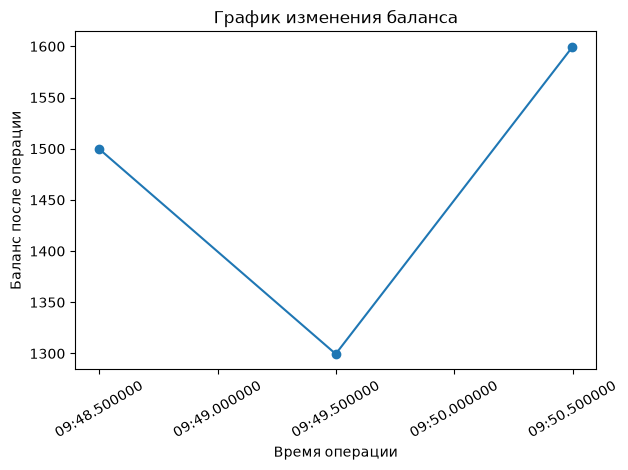

In [11]:
new_account.plot_balance()

# Задание 2

In [12]:
checking_account = CheckingAccount("Петр Петров", 2000)
savings_account = SavingsAccount("Александр Сидоров", 10000, 5)

In [13]:
savings_account.interest()
savings_account.get_balance()

Decimal('10500.00')

In [14]:
try:
    savings_account.withdraw(6000)  # больше 50% баланса
except InvalidAmount as error:
    print(error)

Неверно введена сумма снятия


In [15]:
savings_account.withdraw(5000)  # ровно 50% — можно
savings_account.get_logs()

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
1,0fe6b5de,14.10.2026 18:09:50,interest,500.00,10 500.00,success
2,c8caf81a,14.10.2026 18:09:50,withdraw,6 000.00,10 500.00,fail
3,1d22b102,14.10.2026 18:09:50,withdraw,5 000.00,5 500.00,success


In [16]:
# последние 2 успешные операции на сумму от 500
savings_account.logs_analysis(500, 2)

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
1,0fe6b5de,14.10.2026 18:09:50,interest,500.00,10 500.00,success
3,1d22b102,14.10.2026 18:09:50,withdraw,5 000.00,5 500.00,success


In [17]:
try:
    CheckingAccount("иван петров")
except InvalidName as error:
    print(error)

Неверное имя владельца счета


In [18]:
try:
    checking_account.deposit(-5)
except InvalidAmount as error:
    print(error)

Неверно введена сумма пополнения


# Дополнительное задание. Перевод между счетами

In [19]:
transfer(checking_account, savings_account, 500)
print(checking_account.get_balance(), savings_account.get_balance())

1500.00 6000.00


In [20]:
# сумма больше 50% баланса сберегательного счета: перевод отклонен
try:
    transfer(savings_account, checking_account, 6000)
except InvalidAmount as error:
    print(error)
print(checking_account.get_balance(), savings_account.get_balance())

Неверно введена сумма снятия
1500.00 6000.00


In [21]:
# общий ID операции у отправителя и получателя
checking_account.get_logs(last=1)

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
2,fdfdc08f,14.10.2026 18:09:50,withdraw,500.00,1 500.00,success


In [22]:
savings_account.get_logs(last=3)

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
3,1d22b102,14.10.2026 18:09:50,withdraw,5 000.00,5 500.00,success
4,fdfdc08f,14.10.2026 18:09:50,deposit,500.00,6 000.00,success
5,996d0215,14.10.2026 18:09:50,withdraw,6 000.00,6 000.00,fail


# Задание 3

In [23]:
checking = CheckingAccount(
    "Алексей Алексеев", 1200, account_number="ACC-100001"
)
accepted_1, rejected_1 = checking.load_history("transactions_dirty.csv")
checking.get_balance()

Decimal('4864.00')

In [24]:
checking.get_logs(last=5)

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
13,631d6b91,14.10.2025 22:17:26,deposit,532.00,4 729.00,success
14,77ddfdd4,16.10.2025 22:17:26,withdraw,393.00,4 336.00,success
15,ec6cb740,16.10.2025 22:17:26,deposit,701.00,5 037.00,success
16,b29a493f,17.10.2025 22:17:26,withdraw,308.00,4 729.00,success
17,ddea72ac,18.10.2025 22:17:26,deposit,135.00,4 864.00,success


In [25]:
savings = SavingsAccount("Мария Волкова", 1500, 7, "ACC-100002")
accepted_2, rejected_2 = savings.load_history("transactions_dirty.json")
savings.get_balance()

Decimal('3991.24')

In [26]:
savings.get_logs(last=5)

,ID операции,Дата и время,Операция,Сумма,Баланс после,Статус
14,cd05575c,14.10.2025 22:17:26,withdraw,231.00,3 982.98,success
15,35282162,15.10.2025 22:17:26,interest,274.13,4 257.11,success
16,8df2d801,17.10.2025 22:17:26,withdraw,286.00,3 971.11,success
17,73700b81,20.10.2025 22:17:26,interest,302.13,4 273.24,success
18,7ebfb406,23.10.2025 22:17:26,withdraw,282.00,3 991.24,success


# Дополнительное задание. Отчет об отбраковке

In [27]:
reject_report("ACC-100001", accepted_1, rejected_1)

ACC-100001: принято 17, отклонено 9


,Строк,Номера строк в файле
Причина,,
interest недопустим для счета checking,2,"[11, 17]"
некорректная дата,2,"[14, 18]"
дубликат строки,1,[105]
неверный статус,1,[25]
опечатка в типе операции,1,[16]
пустая сумма,1,[6]
пустой тип операции,1,[9]


In [28]:
reject_report("ACC-100002", accepted_2, rejected_2)

ACC-100002: принято 18, отклонено 9


,Строк,Номера строк в файле
Причина,,
дубликат строки,2,"[101, 104]"
опечатка в типе операции,2,"[38, 49]"
отрицательная или нулевая сумма,2,"[34, 45]"
неверный статус,1,[47]
некорректная дата,1,[29]
пустая сумма,1,[30]
